# Training a linear model (logistic regression)

### Load imports

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    KFold,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.exceptions import UndefinedMetricWarning
from datatypes import CLEAN_SQF
import warnings

# Silence warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)
warnings.filterwarnings("ignore", category=UserWarning)

### Split dataset into training and testing sets

In [12]:
clean_df = pd.read_csv(CLEAN_SQF)

features = clean_df.columns.difference(["USE_OF_FORCE_FLAG"]).values
X = clean_df[features]
y = clean_df["USE_OF_FORCE_FLAG"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=123
)

## Main analysis

### Create a logistic regression model and tune hyperparameters

In [19]:
# Initialize logistic regression model using liblinear as solver
logreg = LogisticRegression(
    solver="liblinear", class_weight="balanced", random_state=123
)

# Define how data should be split, using a specified seed
cv_split = KFold(n_splits=5, shuffle=True, random_state=123)

# Define parameter grid for hyperparameter tuning
param_grid = {
    "penalty": ["l1", "l2"],
    "C": [1.0, 0.1, 0.01, 0.001, 0.0001],
}

scoring = ["accuracy", "precision", "recall", "f1"]

# Initialize GridSearchCV, with tuning based on recall (our primary metric)
grid_search = GridSearchCV(
    logreg,
    param_grid=param_grid,
    scoring=scoring,
    refit="recall",
    cv=cv_split,
    verbose=0,
    return_train_score=True,
)

# Run GridSearchCV
grid_search.fit(X_train, y_train)

print(f"We evaluated 2 regularization penalties and 5 C-values across 5 cross-validation folds, totaling 50 experimental fits. Using recall as our metric, the best hyperparameters were {grid_search.best_params_}, which achieved a score of {grid_search.best_score_:.2f}.")

We evaluated 2 regularization penalties and 5 C-values across 5 cross-validation folds, totaling 50 experimental fits. Using recall as our metric, the best hyperparameters were {'C': 0.01, 'penalty': 'l1'}, which achieved a score of 0.66.


### Display results

 param_C param_penalty  mean_test_accuracy  rank_test_accuracy  mean_test_precision  rank_test_precision  mean_test_recall  rank_test_recall  mean_test_f1  rank_test_f1
    1.00            l1                0.61                   5                 0.31                    3              0.63                 6          0.41             1
    1.00            l2                0.61                   4                 0.31                    2              0.63                 7          0.41             2
    0.10            l1                0.60                   7                 0.30                    6              0.63                 4          0.41             5
    0.10            l2                0.61                   6                 0.30                    4              0.63                 5          0.41             3
    0.01            l1                0.58                  10                 0.30                    8              0.66                 1          0.41 

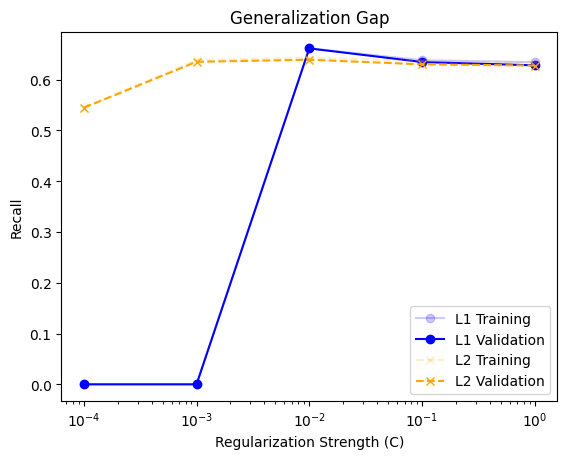

In [14]:
grid_search_results = pd.DataFrame(grid_search.cv_results_)

results_table = grid_search_results[[
    "param_C", "param_penalty",
    "mean_test_accuracy", "rank_test_accuracy",
    "mean_test_precision", "rank_test_precision",
    "mean_test_recall", "rank_test_recall",
    "mean_test_f1", "rank_test_f1"
]].copy()

print(results_table.to_string(index=False, float_format="%.2f"))

plt.figure()

l1_data = grid_search_results[grid_search_results["param_penalty"] == "l1"].sort_values("param_C")
plt.semilogx(l1_data["param_C"], l1_data["mean_train_recall"], 'o-', label="L1 Training", color='blue', alpha=0.2)
plt.semilogx(l1_data["param_C"], l1_data["mean_test_recall"], 'o-', label="L1 Validation", color='blue', alpha=1.0)

l2_data = grid_search_results[grid_search_results["param_penalty"] == "l2"].sort_values("param_C")
plt.semilogx(l2_data["param_C"], l2_data["mean_train_recall"], 'x--', label="L2 Training", color='orange', alpha=0.2)
plt.semilogx(l2_data["param_C"], l2_data["mean_test_recall"], 'x--', label="L2 Validation", color='orange', alpha=1.0)

plt.xlabel("Regularization Strength (C)")
plt.ylabel("Recall")
plt.title("Generalization Gap")
plt.legend()
plt.show()

### Obtain model weights and bias using tuned hyperparameters (based on recall)

In [15]:
# Obtain the best model using the tuned GridSearchCV hyperparameters
best_model = grid_search.best_estimator_

# Extract the weights and bias term from the best model
weights = best_model.coef_[0]
feature_weights = pd.Series(weights, index=X_train.columns)
bias_term = best_model.intercept_[0]

print("Using the tuned hyperparameters, the estimated coefficients are:")
print()
print(feature_weights.sort_values(ascending=False))
print()
print(f"The estimated bias term is {bias_term}")

Using the tuned hyperparameters, the estimated coefficients are:

STOP_LOCATION_PATROL_BORO_NAME_pbms                                        0.494108
SUSPECT_SEX_male                                                           0.156628
STOP_LOCATION_PATROL_BORO_NAME_pbmn                                        0.065233
SUSPECT_REPORTED_AGE_25–44                                                 0.059842
SUSPECTED_CRIME_DESCRIPTION_assault                                        0.040581
SUSPECT_RACE_DESCRIPTION_black                                             0.036225
STOP_WAS_INITIATED_based on c_w on scene                                   0.020718
SUSPECTED_CRIME_DESCRIPTION_cpsp                                           0.000000
STOP_LOCATION_PATROL_BORO_NAME_pbqs                                        0.000000
SUSPECTED_CRIME_DESCRIPTION_auto stripping                                 0.000000
SUSPECTED_CRIME_DESCRIPTION_criminal mischief                              0.000000
SUSPECTED_

### Interpret model

                                   Feature  Raw Coefficient  Odds Ratio Percent Change in Odds
       STOP_LOCATION_PATROL_BORO_NAME_pbms             0.49        1.64                 63.90%
                          SUSPECT_SEX_male             0.16        1.17                 16.96%
       STOP_LOCATION_PATROL_BORO_NAME_pbmn             0.07        1.07                  6.74%
                SUSPECT_REPORTED_AGE_25–44             0.06        1.06                  6.17%
       SUSPECTED_CRIME_DESCRIPTION_assault             0.04        1.04                  4.14%
            SUSPECT_RACE_DESCRIPTION_black             0.04        1.04                  3.69%
  STOP_WAS_INITIATED_based on c_w on scene             0.02        1.02                  2.09%
       STOP_LOCATION_PATROL_BORO_NAME_pbbs            -0.01        0.99                 -0.97%
           SUSPECTED_CRIME_DESCRIPTION_cpw            -0.27        0.76                -23.74%
       STOP_LOCATION_PATROL_BORO_NAME_pbbx        

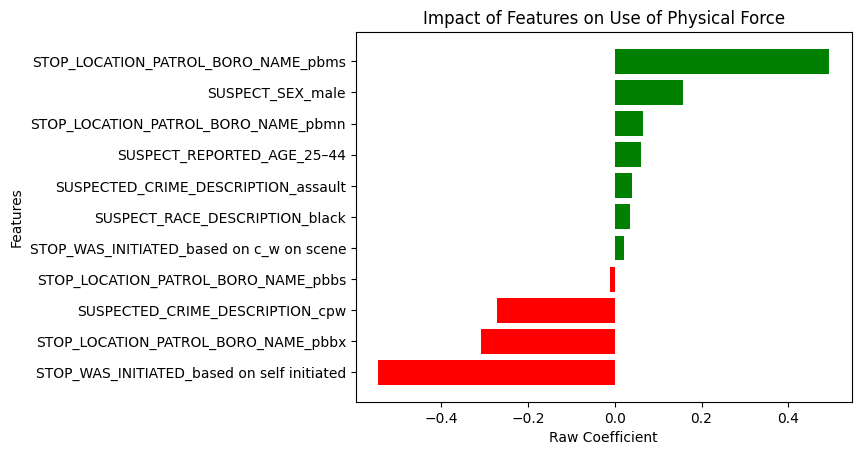

In [16]:
odds_ratios = np.exp(weights)

weights_df = pd.DataFrame(
    {
        "Feature": X_train.columns,
        "Raw Coefficient": weights,
        "Odds Ratio": odds_ratios,
    }
)

weights_df = weights_df[weights_df["Raw Coefficient"] != 0]

weights_df["Percent Change in Odds"] = (weights_df["Odds Ratio"] - 1) * 100

table_df = weights_df.copy()
table_df.sort_values(by="Percent Change in Odds", ascending=False, inplace=True)
table_df["Percent Change in Odds"] = table_df["Percent Change in Odds"].map("{:.2f}%".format)

baseline_prob = 1 / (1 + np.exp(-bias_term))

print(table_df.to_string(index=False, float_format="%.2f"))
print()
print(f"The estimated bias term is {bias_term:.2f}")
print(f"The baseline probability of force (when all dummy variables are 0) is: {baseline_prob * 100:.2f}%")

plot_df = weights_df.copy()
plot_df.sort_values(by="Raw Coefficient", ascending=True, inplace=True)

plt.figure()

colors = ["red" if x < 0 else "green" for x in plot_df["Raw Coefficient"]]

plt.barh(plot_df["Feature"], plot_df["Raw Coefficient"], color=colors)

plt.title("Impact of Features on Use of Physical Force")
plt.xlabel("Raw Coefficient")
plt.ylabel("Features")
plt.show()

### Predict labels on test set and obtain key evaluation metrics from predictions using tuned hyperparameters (based on recall)

              precision    recall  f1-score   support

           0       0.86      0.56      0.68      4107
           1       0.30      0.68      0.41      1131

    accuracy                           0.59      5238
   macro avg       0.58      0.62      0.55      5238
weighted avg       0.74      0.59      0.62      5238



<Figure size 640x480 with 0 Axes>

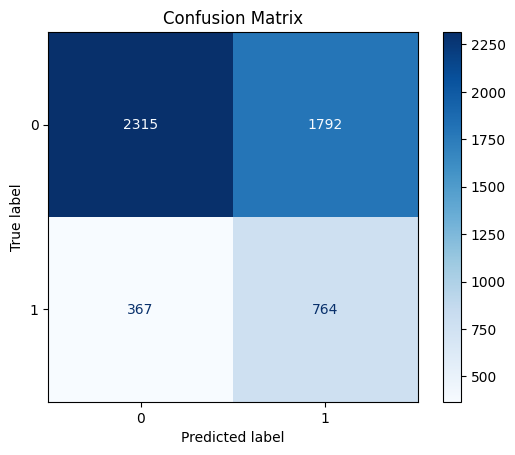

In [17]:
y_pred = best_model.predict(X_test)
print(classification_report(y_test, y_pred))

# Create a confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=best_model.classes_)

plt.figure()
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.show()

## Supplementary analysis
### Predict labels on test set using tuned hyperparameters (based on other metrics for comparison) and obtain key metrics from predictions

Using accuracy: the best C is 0.001 and the best penalty is l1, resulting in a score of 0.7829.
Evaluating the model with these hyperparameters gives us the following metrics.
              precision    recall  f1-score   support

           0       0.78      1.00      0.88      4107
           1       0.00      0.00      0.00      1131

    accuracy                           0.78      5238
   macro avg       0.39      0.50      0.44      5238
weighted avg       0.61      0.78      0.69      5238



<Figure size 640x480 with 0 Axes>

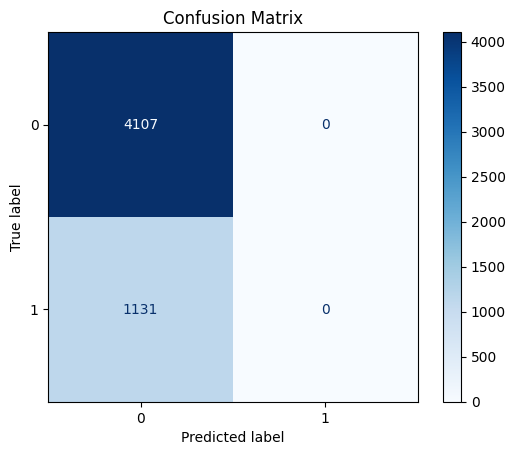


Using precision: the best C is 0.0001 and the best penalty is l2, resulting in a score of 0.3097.
Evaluating the model with these hyperparameters gives us the following metrics.
              precision    recall  f1-score   support

           0       0.85      0.65      0.73      4107
           1       0.31      0.57      0.40      1131

    accuracy                           0.63      5238
   macro avg       0.58      0.61      0.57      5238
weighted avg       0.73      0.63      0.66      5238



<Figure size 640x480 with 0 Axes>

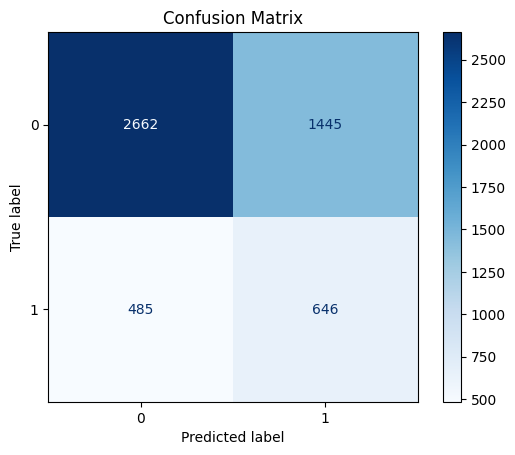


Using f1: the best C is 1.0 and the best penalty is l1, resulting in a score of 0.4107.
Evaluating the model with these hyperparameters gives us the following metrics.
              precision    recall  f1-score   support

           0       0.85      0.60      0.70      4107
           1       0.30      0.63      0.41      1131

    accuracy                           0.60      5238
   macro avg       0.58      0.61      0.55      5238
weighted avg       0.73      0.60      0.64      5238



<Figure size 640x480 with 0 Axes>

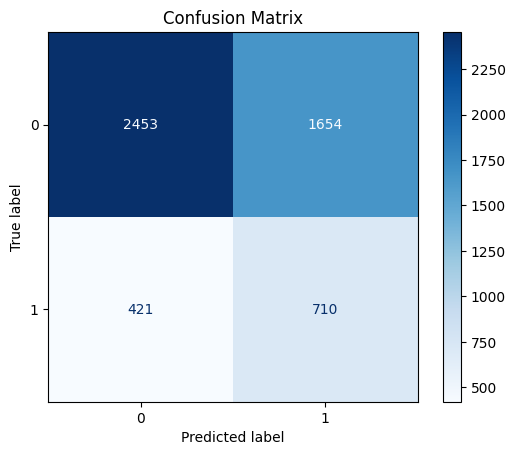

In [18]:
refit_metric = grid_search.refit
scoring_ex_recall = [metric for metric in scoring if metric != refit_metric]

# Loop through scoring metrics
for metric in scoring_ex_recall:
    # Get index of the row with the best score and rank for the given metric
    best_score_index = grid_search_results[f"rank_test_{metric}"].idxmin()

    # Get the parameters and score of the row with the best score and rank
    best_C = grid_search_results.loc[best_score_index, "param_C"]
    best_penalty = grid_search_results.loc[best_score_index, "param_penalty"]
    best_score = grid_search_results.loc[best_score_index, f"mean_test_{metric}"]

    # Build a logistic regression model to predict values using the tuned hyperparameters based on the given metric and evaluate results
    logreg_new = LogisticRegression(
        solver="liblinear",
        class_weight="balanced",
        random_state=123,
        C=best_C,
        penalty=best_penalty,
    ).fit(X_train, y_train)
    y_pred_new = logreg_new.predict(X_test)

    print(
        f"Using {metric}: the best C is {best_C} and the best penalty is {best_penalty}, resulting in a score of {best_score:.4f}."
    )
    print(
        "Evaluating the model with these hyperparameters gives us the following metrics."
    )
    print(classification_report(y_test, y_pred_new))


    cm_new = confusion_matrix(y_test, y_pred_new)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm_new, display_labels=logreg_new.classes_)

    plt.figure()
    disp.plot(cmap="Blues", values_format="d")
    plt.title("Confusion Matrix")
    plt.show()

    print()